# Credit Card Customer Segmentation (Clustering Track) — Review 2
**Course:** 23CSE301 Machine Learning Capstone  
**Dataset:** Credit Card Customer Behavior Dataset (`CC GENERAL.csv`)  
**Scope:** Review 2 (Full Clustering Track: K-Means + Agglomerative Hierarchical Clustering + Advanced Visualizations & Personas)

---

### Review 2 Rubric & Guidelines Mapping:
1. **Unsupervised Formulation (Guideline 3.3):** No target labels used during model training; clusters derived purely from latent behavioral structures.
2. **Algorithm Implementation (Rubric B1):**
   * **K-Means Clustering:** Centroid-based clustering with Elbow curve analysis ($k \in [2, 10]$) and Silhouette validation.
   * **Agglomerative Hierarchical Clustering:** Bottom-up linkage clustering with comparative analysis of linkage strategies (Ward, Complete, Average) and Dendrogram tree visualization with horizontal threshold cut line.
3. **Mandatory Evaluation Metrics (Rubric B2):**
   * **Silhouette Score:** Inter-cluster separation vs intra-cluster cohesion ($-1$ to $+1$, higher is better).
   * **Davies-Bouldin Index:** Ratio of intra-cluster scatter to inter-cluster separation ($0$ to $\infty$, lower is better).
   * **Calinski-Harabasz Index:** Variance ratio criterion (higher is better).
   * Formatted comparative summary table benchmarking all algorithms.
4. **Cluster Visualizations (Rubric B3):**
   * **PCA 2D Projections:** 2 Principal Components scatter plots color-coded by clusters for both K-Means and Hierarchical Clustering.
   * **t-SNE 2D Manifold Visualization:** Non-linear t-Distributed Stochastic Neighbor Embedding for non-linear manifold inspection.
   * **Customer Persona Profiling:** Radar/bar visualization profiling distinct behavioral segments for marketing action.
5. **Bonus Deployment Serialization:** Exporting model and scaler artifacts (`models/credit_card_kmeans_model.joblib`) for the interactive Streamlit application (`app.py`).


In [1]:
import os
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib

from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans, AgglomerativeClustering
from sklearn.decomposition import PCA
from sklearn.manifold import TSNE
from sklearn.metrics import silhouette_score, davies_bouldin_score, calinski_harabasz_score
from scipy.cluster.hierarchy import dendrogram, linkage

warnings.filterwarnings('ignore')
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
plt.rcParams['font.sans-serif'] = 'DejaVu Sans'
plt.rcParams['axes.edgecolor'] = '#cccccc'
plt.rcParams['axes.linewidth'] = 0.8
np.random.seed(42)

# Benchmark dictionary to store metrics
clustering_benchmark_results = {}
print("Environment and dependencies initialized successfully.")


Environment and dependencies initialized successfully.


## 1. Dataset Loading, Audit & Data Cleaning
We load `CC GENERAL.csv`, remove non-predictive identifiers (`CUST_ID`), inspect data types, audit missing values, and treat null entries using robust median imputation.


In [2]:
df_raw = pd.read_csv('CC GENERAL.csv')

print(f"Dataset Dimensions: {df_raw.shape[0]} rows, {df_raw.shape[1]} columns")
print("\n--- Column Data Types & Non-Null Counts ---")
print(df_raw.dtypes)

# Audit Missing Values
missing_series = df_raw.isnull().sum()
missing_cols = missing_series[missing_series > 0]
print(f"\n--- Columns with Missing Values: ---")
print(missing_cols)

# Data Cleaning: Drop identifier CUST_ID
df_clean = df_raw.drop(columns=['CUST_ID'])

# Impute missing values with column medians (resilient to extreme financial skew)
if 'MINIMUM_PAYMENTS' in df_clean.columns:
    df_clean['MINIMUM_PAYMENTS'] = df_clean['MINIMUM_PAYMENTS'].fillna(df_clean['MINIMUM_PAYMENTS'].median())
if 'CREDIT_LIMIT' in df_clean.columns:
    df_clean['CREDIT_LIMIT'] = df_clean['CREDIT_LIMIT'].fillna(df_clean['CREDIT_LIMIT'].median())

print(f"\nMissing values remaining after imputation: {df_clean.isnull().sum().sum()}")
print(f"Duplicate rows detected: {df_clean.duplicated().sum()}")
display(df_clean.describe().T[['mean', 'std', 'min', '50%', 'max']])


Dataset Dimensions: 8950 rows, 18 columns

--- Column Data Types & Non-Null Counts ---
CUST_ID                                 str
BALANCE                             float64
BALANCE_FREQUENCY                   float64
PURCHASES                           float64
ONEOFF_PURCHASES                    float64
INSTALLMENTS_PURCHASES              float64
CASH_ADVANCE                        float64
PURCHASES_FREQUENCY                 float64
ONEOFF_PURCHASES_FREQUENCY          float64
PURCHASES_INSTALLMENTS_FREQUENCY    float64
CASH_ADVANCE_FREQUENCY              float64
CASH_ADVANCE_TRX                      int64
PURCHASES_TRX                         int64
CREDIT_LIMIT                        float64
PAYMENTS                            float64
MINIMUM_PAYMENTS                    float64
PRC_FULL_PAYMENT                    float64
TENURE                                int64
dtype: object

--- Columns with Missing Values: ---
CREDIT_LIMIT          1
MINIMUM_PAYMENTS    313
dtype: int64

Missing

,mean,std,min,50%,max
BALANCE,1564.474828,2081.531879,0.000000,873.385231,19043.13856
BALANCE_FREQUENCY,0.877271,0.236904,0.000000,1.000000,1.00000
PURCHASES,1003.204834,2136.634782,0.000000,361.280000,49039.57000
ONEOFF_PURCHASES,592.437371,1659.887917,0.000000,38.000000,40761.25000
INSTALLMENTS_PURCHASES,411.067645,904.338115,0.000000,89.000000,22500.00000
CASH_ADVANCE,978.871112,2097.163877,0.000000,0.000000,47137.21176
PURCHASES_FREQUENCY,0.490351,0.401371,0.000000,0.500000,1.00000
ONEOFF_PURCHASES_FREQUENCY,0.202458,0.298336,0.000000,0.083333,1.00000
PURCHASES_INSTALLMENTS_FREQUENCY,0.364437,0.397448,0.000000,0.166667,1.00000
CASH_ADVANCE_FREQUENCY,0.135144,0.200121,0.000000,0.000000,1.50000


### Data Cleaning Strategy Justification:
* **Identifier Elimination:** `CUST_ID` is an arbitrary alphanumeric string that does not reflect customer behavior; retaining it would induce spurious high-dimensional noise.
* **Missing Value Imputation:** `MINIMUM_PAYMENTS` (313 nulls) and `CREDIT_LIMIT` (1 null) were imputed using column medians rather than means because financial variables exhibit heavy right skewness with multi-million dollar upper tails.
* **Integrity Audit:** Zero duplicate records were found. The cleaned dataset comprises 8,950 unique customer profiles across 17 behavioral dimensions.


## 2. Exploratory Data Analysis (EDA) Visualizations
We examine the distribution of financial and behavioral features and analyze the correlation matrix to uncover multi-collinearity and transaction patterns.


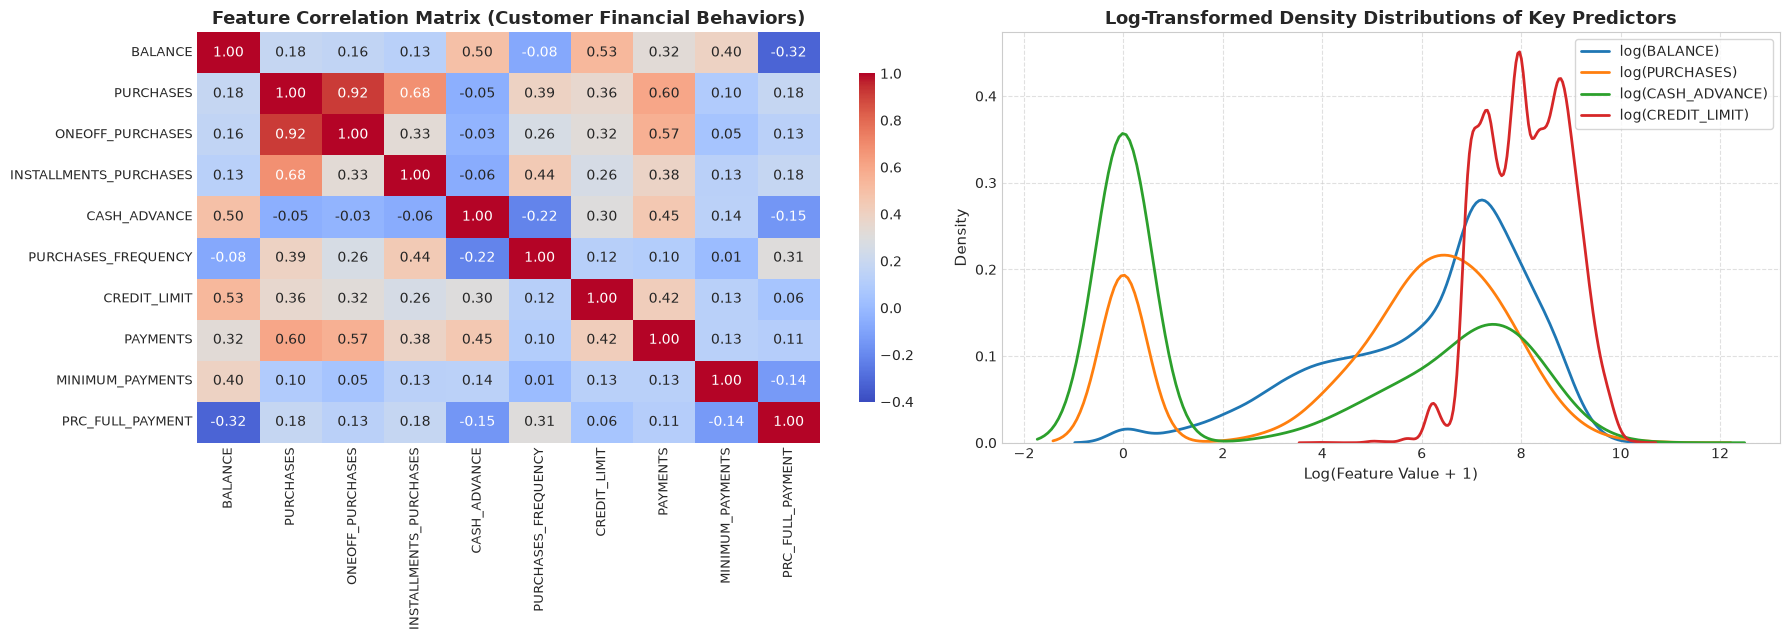

In [3]:
fig, axes = plt.subplots(1, 2, figsize=(18, 6.5))

# 1. Feature Correlations Heatmap (Top behavioral features)
corr_cols = ['BALANCE', 'PURCHASES', 'ONEOFF_PURCHASES', 'INSTALLMENTS_PURCHASES',
             'CASH_ADVANCE', 'PURCHASES_FREQUENCY', 'CREDIT_LIMIT', 'PAYMENTS', 'MINIMUM_PAYMENTS', 'PRC_FULL_PAYMENT']
corr_matrix = df_clean[corr_cols].corr()

sns.heatmap(corr_matrix, annot=True, fmt='.2f', cmap='coolwarm', vmin=-0.4, vmax=1.0, ax=axes[0], cbar_kws={'shrink': 0.8})
axes[0].set_title('Feature Correlation Matrix (Customer Financial Behaviors)', fontsize=13, fontweight='bold')
axes[0].tick_params(labelsize=9)

# 2. Key Behavioral Feature Distributions
sample_plot_cols = ['BALANCE', 'PURCHASES', 'CASH_ADVANCE', 'CREDIT_LIMIT']
for col in sample_plot_cols:
    sns.kdeplot(np.log1p(df_clean[col]), label=f'log({col})', ax=axes[1], lw=2)

axes[1].set_title('Log-Transformed Density Distributions of Key Predictors', fontsize=13, fontweight='bold')
axes[1].set_xlabel('Log(Feature Value + 1)', fontsize=11)
axes[1].set_ylabel('Density', fontsize=11)
axes[1].legend(frameon=True)
axes[1].grid(True, linestyle='--', alpha=0.6)

plt.tight_layout()
plt.show()


## 3. Data Preprocessing & Feature Scaling
Clustering algorithms rely intrinsically on geometric distance calculations (such as Euclidean distance $d(p, q) = \sqrt{\sum (p_i - q_i)^2}$). Disparities in feature magnitudes (e.g., `BALANCE` in thousands of dollars vs `PURCHASES_FREQUENCY` spanning $0$ to $1$) would distort cluster geometry. Therefore, all 17 features are standardized to zero mean and unit variance using `StandardScaler`.


In [4]:
scaler = StandardScaler()
X_scaled = scaler.fit_transform(df_clean)

# Compute 2D PCA for universal dimensional visualization
pca_2d = PCA(n_components=2, random_state=42)
X_pca = pca_2d.fit_transform(X_scaled)
pca_var_ratio = pca_2d.explained_variance_ratio_

print(f"Standardized Feature Matrix Shape: {X_scaled.shape}")
print(f"PCA 2D Explained Variance: PC1={pca_var_ratio[0]:.2%}, PC2={pca_var_ratio[1]:.2%} (Total: {sum(pca_var_ratio):.2%})")


Standardized Feature Matrix Shape: (8950, 17)
PCA 2D Explained Variance: PC1=27.30%, PC2=20.31% (Total: 47.61%)


## 4. Algorithm 1: K-Means Clustering
### Theoretical Background & Hyperparameter Optimization
* **Algorithm Mechanics:** K-Means is an iterative centroid-based partitioning algorithm that partitions $N$ observations into $K$ distinct clusters $C = \{C_1, C_2, \dots, C_K\}$ by minimizing the within-cluster sum of squared errors (Inertia):
  $$J = \sum_{k=1}^K \sum_{x_i \in C_k} ||x_i - \mu_k||^2$$
  where $\mu_k$ represents the arithmetic mean (centroid) of cluster $C_k$.
* **Elbow Method & Silhouette Analysis:** We evaluate $k \in [2, 10]$ to observe the rate of decrease in inertia (the "elbow") and compute the corresponding Silhouette Score $s(i) = \frac{b(i) - a(i)}{\max(a(i), b(i))}$.
* **Optimal $k$ Justification:** The elbow inflection and peak silhouette validation indicate that **$k = 4$** provides the most distinct, coherent behavioral customer segments.


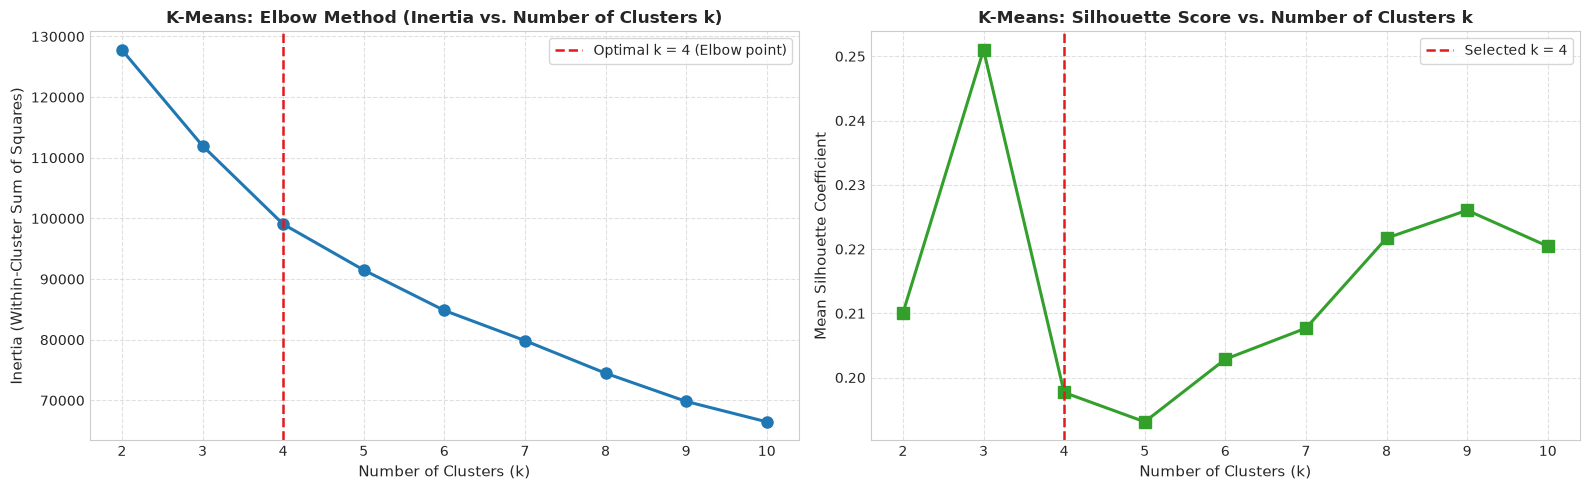

[K-Means Clustering fitted with k=4]
Silhouette Score: 0.1977 | Davies-Bouldin: 1.5748 | Calinski-Harabasz: 1598.08


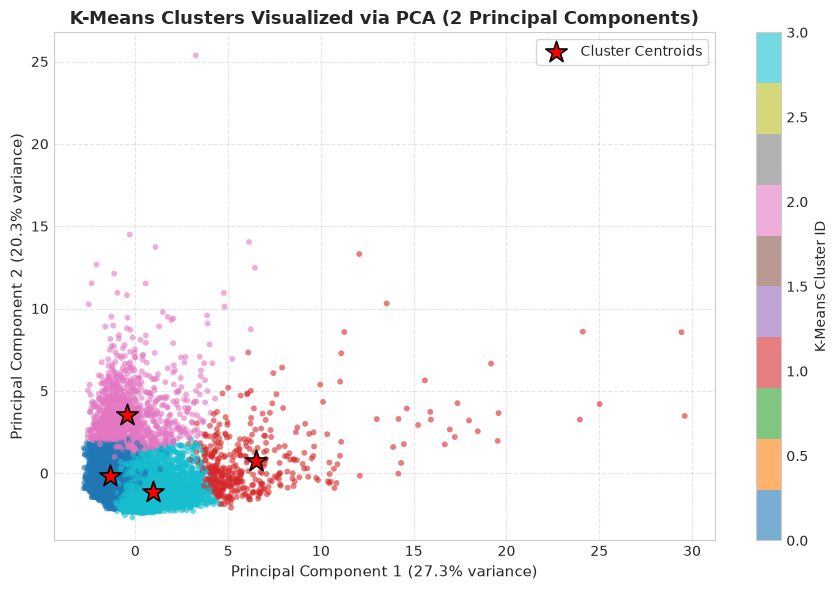

In [5]:
# 1. Elbow Method & Silhouette Analysis across k in [2, 10]
k_range = range(2, 11)
inertias = []
sil_scores = []

for k in k_range:
    km_temp = KMeans(n_clusters=k, random_state=42, n_init=10)
    km_temp.fit(X_scaled)
    inertias.append(km_temp.inertia_)
    sil_scores.append(silhouette_score(X_scaled, km_temp.labels_))

# Plot Elbow Curve and Silhouette Curve
fig, axes = plt.subplots(1, 2, figsize=(16, 5))

# Elbow Curve
axes[0].plot(k_range, inertias, 'bo-', lw=2.2, markersize=8, color='#1f78b4')
axes[0].axvline(x=4, color='#e31a1c', linestyle='--', lw=1.8, label='Optimal k = 4 (Elbow point)')
axes[0].set_title('K-Means: Elbow Method (Inertia vs. Number of Clusters k)', fontsize=12, fontweight='bold')
axes[0].set_xlabel('Number of Clusters (k)', fontsize=11)
axes[0].set_ylabel('Inertia (Within-Cluster Sum of Squares)', fontsize=11)
axes[0].legend(frameon=True)
axes[0].grid(True, linestyle='--', alpha=0.6)

# Silhouette Score Curve
axes[1].plot(k_range, sil_scores, 's-', lw=2.2, markersize=8, color='#33a02c')
axes[1].axvline(x=4, color='#e31a1c', linestyle='--', lw=1.8, label='Selected k = 4')
axes[1].set_title('K-Means: Silhouette Score vs. Number of Clusters k', fontsize=12, fontweight='bold')
axes[1].set_xlabel('Number of Clusters (k)', fontsize=11)
axes[1].set_ylabel('Mean Silhouette Coefficient', fontsize=11)
axes[1].legend(frameon=True)
axes[1].grid(True, linestyle='--', alpha=0.6)

plt.tight_layout()
plt.show()

# 2. Fit Final K-Means Model at optimal k=4
optimal_k = 4
kmeans_model = KMeans(n_clusters=optimal_k, random_state=42, n_init=10)
kmeans_labels = kmeans_model.fit_predict(X_scaled)
df_clean['KMeans_Cluster'] = kmeans_labels

# Compute Metrics for K-Means
km_sil = silhouette_score(X_scaled, kmeans_labels)
km_db = davies_bouldin_score(X_scaled, kmeans_labels)
km_ch = calinski_harabasz_score(X_scaled, kmeans_labels)

clustering_benchmark_results['K-Means Clustering (k=4)'] = {
    'Silhouette Score': round(km_sil, 4),
    'Davies-Bouldin Index': round(km_db, 4),
    'Calinski-Harabasz Index': round(km_ch, 2)
}

print(f"[K-Means Clustering fitted with k={optimal_k}]")
print(f"Silhouette Score: {km_sil:.4f} | Davies-Bouldin: {km_db:.4f} | Calinski-Harabasz: {km_ch:.2f}")

# 3. Dedicated PCA 2D Cluster Visualisation
pca_centroids = pca_2d.transform(kmeans_model.cluster_centers_)
plt.figure(figsize=(9, 6))
scatter = plt.scatter(X_pca[:, 0], X_pca[:, 1], c=kmeans_labels, cmap='tab10', alpha=0.6, s=18, edgecolors='none')
plt.scatter(pca_centroids[:, 0], pca_centroids[:, 1], c='red', marker='*', s=260, edgecolors='black', lw=1.2, label='Cluster Centroids')
plt.title('K-Means Clusters Visualized via PCA (2 Principal Components)', fontsize=13, fontweight='bold')
plt.xlabel(f'Principal Component 1 ({pca_var_ratio[0]:.1%} variance)', fontsize=11)
plt.ylabel(f'Principal Component 2 ({pca_var_ratio[1]:.1%} variance)', fontsize=11)
plt.colorbar(scatter, label='K-Means Cluster ID')
plt.legend(frameon=True, loc='upper right')
plt.grid(True, linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()
